# Econ 4850 · Homework 3 companion: SIR model demonstration

Geoffrey Kam, Washington University in St. Louis · Spring 2025

## The SIR model

The SIR model splits a population of fixed size $N$ into three groups: susceptible ($S$), infected ($I$) and recovered ($R$), with $S + I + R = N$. Its dynamics are described by a system of ordinary differential equations:

$$
\frac{dS}{dt} = -\beta \frac{S I}{N}, \qquad
\frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \qquad
\frac{dR}{dt} = \gamma I,
$$

where $\beta$ is the transmission rate and $\gamma$ is the recovery rate. We use $N = 1000$, $\beta = 0.3$, $\gamma = 0.1$ and the initial conditions $I(0) = 1$, $R(0) = 0$ and $S(0) = N - I(0) - R(0) = 999$, and simulate the epidemic over $t \in [0, 160]$ days. (In the code, `R0` denotes the initial number of recovered individuals $R(0)$, not the basic reproduction number.)

This notebook solves the model in two ways and compares the results:

1. with SciPy's ODE solver `scipy.integrate.odeint`, used as the benchmark;
2. with the explicit Euler method and a time step of $\Delta t = 1$ day, which updates each group using its rate of change at the current date, for example
$$
S_{n+1} = S_n + \Delta t \left(-\beta \frac{S_n I_n}{N}\right).
$$

To compare the two solutions on the same time grid, the Euler solution is interpolated with a cubic spline.

## Parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.interpolate import UnivariateSpline

# SIR model parameters
N = 1000                # total population
I0, R0 = 1, 0           # initial infected and recovered individuals
S0 = N - I0 - R0        # initial susceptible individuals
beta, gamma = 0.3, 0.1  # transmission and recovery rates

# Time grid for the odeint solution
t_ode = np.linspace(0, 160, 1600)

## Benchmark solution with `odeint`

In [2]:
def deriv(y, t, beta, gamma, N):
    """Right-hand side of the SIR system."""
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return dSdt, dIdt, dRdt


y0 = (S0, I0, R0)
solution_odeint = odeint(deriv, y0, t_ode, args=(beta, gamma, N))
S_ode, I_ode, R_ode = solution_odeint.T

## Explicit Euler method

In [3]:
dt = 1
t_euler = np.arange(0, 160 + dt, dt)
num_steps = len(t_euler)
S_euler = np.zeros(num_steps)
I_euler = np.zeros(num_steps)
R_euler = np.zeros(num_steps)

# Initial conditions
S_euler[0], I_euler[0], R_euler[0] = S0, I0, R0

# Euler integration loop
for n in range(num_steps - 1):
    dSdt = -beta * S_euler[n] * I_euler[n] / N
    dIdt = beta * S_euler[n] * I_euler[n] / N - gamma * I_euler[n]
    dRdt = gamma * I_euler[n]

    S_euler[n + 1] = S_euler[n] + dt * dSdt
    I_euler[n + 1] = I_euler[n] + dt * dIdt
    R_euler[n + 1] = R_euler[n] + dt * dRdt

## Spline interpolation of the Euler solution

In [4]:
# s=0 forces the spline to pass through every Euler point
spline_S = UnivariateSpline(t_euler, S_euler, s=0)
spline_I = UnivariateSpline(t_euler, I_euler, s=0)
spline_R = UnivariateSpline(t_euler, R_euler, s=0)

S_euler_interp = spline_S(t_ode)
I_euler_interp = spline_I(t_ode)
R_euler_interp = spline_R(t_ode)

## Comparison

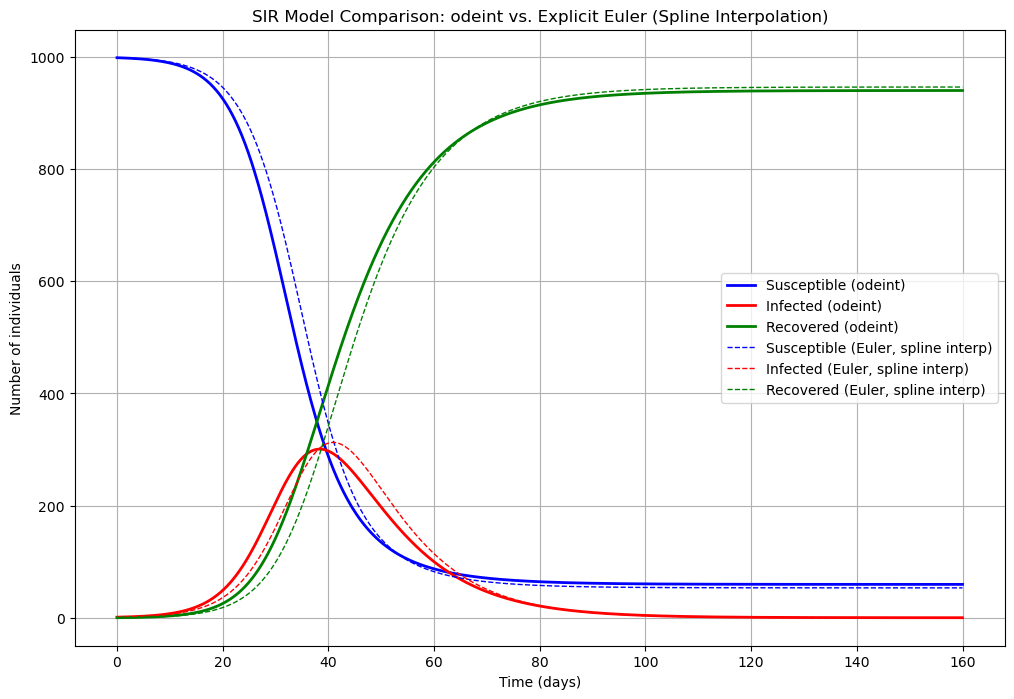

In [5]:
plt.figure(figsize=(12, 8))

# odeint solutions (solid lines)
plt.plot(t_ode, S_ode, 'b-', lw=2, label='Susceptible (odeint)')
plt.plot(t_ode, I_ode, 'r-', lw=2, label='Infected (odeint)')
plt.plot(t_ode, R_ode, 'g-', lw=2, label='Recovered (odeint)')

# Euler solutions (dashed lines), spline-interpolated
plt.plot(t_ode, S_euler_interp, 'b--', lw=1,
         label='Susceptible (Euler, spline interp)')
plt.plot(t_ode, I_euler_interp, 'r--', lw=1,
         label='Infected (Euler, spline interp)')
plt.plot(t_ode, R_euler_interp, 'g--', lw=1,
         label='Recovered (Euler, spline interp)')

plt.xlabel('Time (days)')
plt.ylabel('Number of individuals')
plt.title('SIR Model Comparison: odeint vs. Explicit Euler '
          '(Spline Interpolation)')
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# Maximum absolute differences between the two solutions
diff_S = np.abs(S_ode - S_euler_interp)
diff_I = np.abs(I_ode - I_euler_interp)
diff_R = np.abs(R_ode - R_euler_interp)

print("Maximum absolute differences using spline interpolation:")
print(f"Susceptible: {np.max(diff_S):.4f}")
print(f"Infected:    {np.max(diff_I):.4f}")
print(f"Recovered:   {np.max(diff_R):.4f}")

Maximum absolute differences using spline interpolation:
Susceptible: 96.9530
Infected:    44.3533
Recovered:   73.6933
